<a href="https://colab.research.google.com/github/Mrsayem/Coding-Task/blob/main/pos_freezing_research_cleaned.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install "transformers==4.57.1" "scikit-learn>=1.4" "tqdm>=4.65" "requests>=2.31"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 56.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 71.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import gc
import hashlib
import json
import random
import shutil
import time
from collections import Counter, defaultdict
from contextlib import nullcontext
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as torch_func
from sklearn.metrics import classification_report, f1_score
from torch.utils.data import DataLoader, Dataset, Subset
from tqdm.auto import tqdm
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    get_linear_schedule_with_warmup,
)
import transformers

random_seed = 42
model_name = "distilbert/distilbert-base-multilingual-cased"
ud_version = "r2.18"
train_size = 2000
val_size = 300
test_size = 500
max_length = 96
epochs = 3
batch_size = 16
learning_rate = 5e-5
weight_decay = 0.01
frozen_blocks = 3
min_ambig_freq = 4
rare_max_freq = 3
probe_sentences = 32
bootstrap_repeats = 2000
save_weights = False

output_dir = Path("/content/pos_freezing_research") if Path("/content").exists() else Path.cwd() / "pos_freezing_research"
data_dir = output_dir / "data"
output_dir.mkdir(parents=True, exist_ok=True)
data_dir.mkdir(parents=True, exist_ok=True)
start_wall = time.perf_counter()

tags = [
    "ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM",
    "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X",
]
label2id = {tag: idx for idx, tag in enumerate(tags)}
id2label = {idx: tag for tag, idx in label2id.items()}

def set_seed(seed=random_seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
amp = device.type == "cuda"
print("Device:", device, torch.cuda.get_device_name(0) if amp else "CPU (slow for full run)")
print("PyTorch:", torch.__version__, "Transformers:", transformers.__version__)
assert 0 < frozen_blocks < 6
assert min_ambig_freq > rare_max_freq
assert bootstrap_repeats >= 100

Device: cuda Tesla T4
PyTorch: 2.11.0+cu130 Transformers: 4.57.1


In [3]:
ud_base = f"https://raw.githubusercontent.com/UniversalDependencies/UD_English-EWT/{ud_version}/"
filenames = {
    "train": "en_ewt-ud-train.conllu",
    "dev": "en_ewt-ud-dev.conllu",
    "test": "en_ewt-ud-test.conllu",
}
file_sha256 = {}
for split, filename in filenames.items():
    path = data_dir / filename
    if not path.is_file() or path.stat().st_size == 0:
        print(f"Downloading official {split} ({ud_version}) ...")
        response = requests.get(ud_base + filename, timeout=120)
        response.raise_for_status()
        path.write_bytes(response.content)
    file_sha256[split] = hashlib.sha256(path.read_bytes()).hexdigest()

def read_conllu(path):
    examples, words, upos = [], [], []
    sentence_id = None
    def commit():
        if words:
            examples.append({"sent_id": sentence_id, "tokens": list(words), "tags": list(upos)})
    with open(path, "r", encoding="utf-8") as handle:
        for raw in handle:
            line = raw.rstrip("\n\r")
            if not line.strip():
                commit()
                words, upos, sentence_id = [], [], None
                continue
            if line.startswith("# sent_id = "):
                sentence_id = line.split("=", 1)[1].strip()
            elif not line.startswith("#"):
                cols = line.split("\t")
                if len(cols) != 10:
                    raise ValueError(f"Malformed CoNLL-U token line in {path}: {line[:100]}")
                if not cols[0].isdigit():
                    continue
                if cols[3] not in label2id:
                    raise ValueError(f"Unknown UPOS tag: {cols[3]}")
                words.append(cols[1]); upos.append(cols[3])
    commit()
    assert all(len(e["tokens"]) == len(e["tags"]) > 0 for e in examples)
    return examples

all_data = {split: read_conllu(data_dir / fn) for split, fn in filenames.items()}
rng = random.Random(random_seed)
train_sentences = rng.sample(all_data["train"], min(train_size, len(all_data["train"])))
val_sentences = rng.sample(all_data["dev"], min(val_size, len(all_data["dev"])))
test_sentences = rng.sample(all_data["test"], min(test_size, len(all_data["test"])))
for name, rows in [("train", train_sentences), ("validation", val_sentences), ("test", test_sentences)]:
    print(f"{name:>10}: {len(rows):5,} sentences; {sum(len(r['tokens']) for r in rows):7,} UD words")
assert train_sentences and val_sentences and test_sentences

     train: 2,000 sentences;  32,252 UD words
validation:   300 sentences;   3,773 UD words
      test:   500 sentences;   6,096 UD words


In [4]:
train_lexicon = defaultdict(Counter)
train_tags = Counter()
for sentence in train_sentences:
    for word, tag in zip(sentence["tokens"], sentence["tags"]):
        train_lexicon[word.casefold()][tag] += 1
        train_tags[tag] += 1
global_prior_tag = sorted(train_tags, key=lambda tag: (-train_tags[tag], tag))[0]

def lexical_properties(word, gold_tag):
    distribution = train_lexicon.get(word.casefold(), Counter())
    freq = sum(distribution.values())
    majority = sorted(distribution, key=lambda tag: (-distribution[tag], tag))[0] if freq else global_prior_tag
    ambiguous_type = freq >= min_ambig_freq and len(distribution) >= 2
    if freq == 0:
        category = "unseen"
    elif freq <= rare_max_freq:
        category = "rare_seen"
    elif ambiguous_type:
        category = "frequent_ambiguous"
    else:
        category = "frequent_single_tag"
    return {
        "train_freq": freq,
        "train_tag_types": len(distribution),
        "lexical_prior_tag": majority,
        "lexical_group": category,
        "ambiguous_type": bool(ambiguous_type),
        "counterprior": bool(ambiguous_type and gold_tag != majority),
        "prior_consistent": bool(ambiguous_type and gold_tag == majority),
    }

_toy = defaultdict(Counter)
_toy["can"].update({"AUX": 3, "NOUN": 1})
_previous = train_lexicon
try:
    train_lexicon = _toy
    assert lexical_properties("CAN", "NOUN")["counterprior"]
    assert lexical_properties("can", "AUX")["prior_consistent"]
    assert lexical_properties("unknownword", "NOUN")["lexical_group"] == "unseen"
finally:
    train_lexicon = _previous
print("Lexical-prior diagnostic: toy checks passed; training vocabulary =", len(train_lexicon))

Lexical-prior diagnostic: toy checks passed; training vocabulary = 6206


In [5]:
tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
assert tokenizer.is_fast, "word_ids() alignment requires a fast tokenizer"

class posDataset(Dataset):
    def __init__(self, sentences, split):
        self.items = []
        self.word_rows = []
        self.total_words = sum(len(s["tokens"]) for s in sentences)
        for sentence_i, sent in enumerate(tqdm(sentences, desc=f"Encoding {split}")):
            encoded = tokenizer(
                sent["tokens"], is_split_into_words=True,
                truncation=True, max_length=max_length,
                padding=False, return_attention_mask=True,
            )
            ids = encoded.word_ids()
            pieces_per_word = Counter(x for x in ids if x is not None)
            complete_word_ids = set(pieces_per_word)
            if len(encoded["input_ids"]) >= max_length:
                untruncated = tokenizer(
                    sent["tokens"], is_split_into_words=True,
                    truncation=False, padding=False,
                )
                full_wordpiece_counts = Counter(x for x in untruncated.word_ids() if x is not None)
                complete_word_ids = {
                    word_id for word_id, count in pieces_per_word.items()
                    if count == full_wordpiece_counts[word_id]
                }
            labels = []
            previous = None
            for wid in ids:
                if wid is None or wid == previous or wid not in complete_word_ids:
                    labels.append(-100)
                else:
                    assert wid < len(sent["tokens"])
                    gold = sent["tags"][wid]
                    labels.append(label2id[gold])
                    self.word_rows.append({
                        "sentence_index": sentence_i,
                        "source_sent_id": sent["sent_id"] or f"{split}-{sentence_i}",
                        "word_index": wid,
                        "word": sent["tokens"][wid],
                        "gold": gold,
                        "gold_id": label2id[gold],
                        "subword_count": pieces_per_word[wid],
                        "fragmented": bool(pieces_per_word[wid] > 1),
                        **lexical_properties(sent["tokens"][wid], gold),
                    })
                previous = wid
            item = {
                "input_ids": encoded["input_ids"],
                "attention_mask": encoded["attention_mask"],
                "labels": labels,
            }
            assert len(item["input_ids"]) == len(item["labels"])
            self.items.append(item)
        self.labeled_words = len(self.word_rows)
        assert self.labeled_words == sum(sum(int(y != -100) for y in s["labels"]) for s in self.items)
        assert self.labeled_words > 0

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]

train_ds = posDataset(train_sentences, "train")
val_ds = posDataset(val_sentences, "dev")
test_ds = posDataset(test_sentences, "test")

collator = DataCollatorForTokenClassification(
    tokenizer=tokenizer, padding=True, pad_to_multiple_of=8,
    label_pad_token_id=-100, return_tensors="pt",
)

def loader_for(ds, *, shuffle=False):
    return DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(random_seed) if shuffle else None,
        collate_fn=collator, num_workers=0, pin_memory=amp,
    )

val_loader = loader_for(val_ds)
test_loader = loader_for(test_ds)
probe_n = min(probe_sentences, len(val_ds))
probe_loader = loader_for(Subset(val_ds, list(range(probe_n))))
probe_count = sum(sum(y != -100 for y in item["labels"]) for item in val_ds.items[:probe_n])
probe_rows = pd.DataFrame(val_ds.word_rows[:probe_count])

for name, ds in [("training", train_ds), ("validation", val_ds), ("test", test_ds)]:
    print(f"{name} first-subword coverage: {ds.labeled_words:,}/{ds.total_words:,} = {ds.labeled_words / ds.total_words:.2%}")
assert probe_count == len(probe_rows)
assert (test_ds.labeled_words <= test_ds.total_words) and len(test_ds.word_rows) > 0
print("Test diagnostic token counts:")
test_groups = pd.DataFrame(test_ds.word_rows)
print(test_groups["lexical_group"].value_counts().to_string())
print("Counter-prior:", int(test_groups["counterprior"].sum()),
      "; prior-consistent:", int(test_groups["prior_consistent"].sum()),
      "; fragmented:", int(test_groups["fragmented"].sum()))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Encoding train:   0%|          | 0/2000 [00:00<?, ?it/s]

Encoding dev:   0%|          | 0/300 [00:00<?, ?it/s]

Encoding test:   0%|          | 0/500 [00:00<?, ?it/s]

training first-subword coverage: 32,130/32,252 = 99.62%
validation first-subword coverage: 3,773/3,773 = 100.00%
test first-subword coverage: 6,096/6,096 = 100.00%
Test diagnostic token counts:
lexical_group
frequent_ambiguous     2508
frequent_single_tag    1970
unseen                  901
rare_seen               717
Counter-prior: 354 ; prior-consistent: 2154 ; fragmented: 928


In [6]:
def autocast_context():
    return torch.autocast(device_type="cuda", dtype=torch.float16) if amp else nullcontext()

def move_batch(batch):
    return {k: v.to(device, non_blocking=amp) for k, v in batch.items()}

@torch.inference_mode()
def evaluate(model, loader, dataset, include_words=False):
    model.eval()
    gold_ids, predicted_ids = [], []
    for raw in loader:
        batch = move_batch(raw)
        with autocast_context():
            logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
        select = batch["labels"] != -100
        gold_ids.extend(batch["labels"][select].cpu().tolist())
        predicted_ids.extend(logits.argmax(-1)[select].cpu().tolist())
    expected = [r["gold_id"] for r in dataset.word_rows]
    assert gold_ids == expected, "Word alignment mismatch: check loader shuffle/order"
    acc = float(np.mean(np.array(gold_ids) == np.array(predicted_ids)))
    macro_f1 = float(f1_score(
        gold_ids, predicted_ids, labels=list(range(len(tags))),
        average="macro", zero_division=0,
    ))
    result = {"accuracy": acc, "macro_f1": macro_f1, "words": len(gold_ids)}
    if include_words:
        result["predictions"] = predicted_ids
        result["gold_ids"] = gold_ids
    return result

@torch.inference_mode()
def take_representation_snapshot(model):
    model.eval()
    states = None
    for raw in probe_loader:
        batch = move_batch(raw)
        with autocast_context():
            hidden_states = model.distilbert(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
                output_hidden_states=True, return_dict=True,
            ).hidden_states
        keep = batch["labels"] != -100
        if states is None:
            states = [[] for _ in range(len(hidden_states))]
        for index, hidden in enumerate(hidden_states):
            states[index].append(hidden[keep].float().cpu())
    snapshots = [torch.cat(parts, dim=0) for parts in states]
    assert all(s.shape[0] == probe_count for s in snapshots)
    return snapshots

def representation_drift(before, after, experiment):
    assert len(before) == len(after) == 7, "DistilBERT should provide embeddings + 6 blocks"
    masks = {
        "all": np.ones(probe_count, dtype=bool),
        "counterprior": probe_rows["counterprior"].to_numpy(dtype=bool),
        "prior_consistent": probe_rows["prior_consistent"].to_numpy(dtype=bool),
    }
    output = []
    for depth, (initial, final) in enumerate(zip(before, after)):
        change = (1 - torch_func.cosine_similarity(initial, final, dim=-1)).clamp(min=0).numpy()
        for group_name, mask in masks.items():
            output.append({
                "experiment": experiment,
                "layer": depth,
                "layer_name": "Embedding" if depth == 0 else f"Block {depth}",
                "slice": group_name,
                "n_words": int(mask.sum()),
                "mean_cosine_drift": float(change[mask].mean()) if mask.any() else float("nan"),
            })
    return pd.DataFrame(output)

In [7]:
def new_model(freeze=False):
    set_seed()
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(tags), id2label=id2label, label2id=label2id,
    )
    if not hasattr(model, "distilbert") or len(model.distilbert.transformer.layer) != 6:
        raise TypeError("Expected the six-block DistilBertForTokenClassification architecture")
    if freeze:
        for p in model.distilbert.embeddings.parameters():
            p.requires_grad_(False)
        for block in model.distilbert.transformer.layer[:frozen_blocks]:
            for p in block.parameters():
                p.requires_grad_(False)
    model.to(device)
    return model

def synchronize():
    if amp:
        torch.cuda.synchronize()

def train_experiment(name, freeze=False):
    wall_start = time.perf_counter()
    gc.collect()
    if amp:
        torch.cuda.empty_cache()
    model = new_model(freeze=freeze)
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    initial_probe = take_representation_snapshot(model)
    print(f"\n=== {name}: {trainable_params:,} / {total_params:,} trainable parameters ===")
    if freeze:
        assert all(not p.requires_grad for p in model.distilbert.embeddings.parameters())
        assert all(not p.requires_grad for block in model.distilbert.transformer.layer[:frozen_blocks] for p in block.parameters())
        assert all(p.requires_grad for block in model.distilbert.transformer.layer[frozen_blocks:] for p in block.parameters())

    train_loader = loader_for(train_ds, shuffle=True)
    optimizer = torch.optim.AdamW(
        (p for p in model.parameters() if p.requires_grad),
        lr=learning_rate, weight_decay=weight_decay,
    )
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=max(1, int(total_steps * 0.1)),
        num_training_steps=total_steps,
    )
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    best_acc, best_f1, best_epoch, best_state = -1.0, -1.0, None, None
    history, seconds = [], 0.0
    if amp:
        torch.cuda.reset_peak_memory_stats()

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        synchronize()
        start = time.perf_counter()
        for raw in tqdm(train_loader, desc=f"{name} epoch {epoch}/{epochs}", leave=False):
            batch = move_batch(raw)
            optimizer.zero_grad(set_to_none=True)
            with autocast_context():
                loss = model(**batch).loss
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f"Non-finite loss for {name}, epoch {epoch}")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                (p for p in model.parameters() if p.requires_grad), max_norm=1.0,
            )
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += float(loss.detach().cpu())
        synchronize()
        elapsed = time.perf_counter() - start
        seconds += elapsed
        val = evaluate(model, val_loader, val_ds, include_words=True)
        val_counter_mask = np.array([r["counterprior"] for r in val_ds.word_rows], dtype=bool)
        val_prior_mask = np.array([r["prior_consistent"] for r in val_ds.word_rows], dtype=bool)
        val_correct = np.asarray(val["gold_ids"]) == np.asarray(val["predictions"])
        counter_acc = float(val_correct[val_counter_mask].mean()) if val_counter_mask.any() else float("nan")
        prior_acc = float(val_correct[val_prior_mask].mean()) if val_prior_mask.any() else float("nan")
        history.append({
            "experiment": name, "epoch": epoch,
            "train_loss": running_loss / len(train_loader),
            "val_accuracy": val["accuracy"], "val_macro_f1": val["macro_f1"],
            "val_counterprior_accuracy": counter_acc,
            "val_counterprior_words": int(val_counter_mask.sum()),
            "val_prior_consistent_accuracy": prior_acc,
            "val_prior_consistent_words": int(val_prior_mask.sum()),
            "epoch_train_seconds": elapsed,
        })
        print(f"Epoch {epoch} | loss {history[-1]['train_loss']:.4f} | "
              f"val acc {val['accuracy']:.2%} | macro-F1 {val['macro_f1']:.4f} | "
              f"train {elapsed:.1f}s")
        if (val["accuracy"] > best_acc or
            (val["accuracy"] == best_acc and val["macro_f1"] > best_f1)):
            best_acc, best_f1, best_epoch = val["accuracy"], val["macro_f1"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    assert best_state is not None
    model.load_state_dict(best_state)
    final_probe = take_representation_snapshot(model)
    drift = representation_drift(initial_probe, final_probe, name)
    if freeze:
        fixed_drift = drift[(drift["slice"] == "all") & (drift["layer"] <= frozen_blocks)]
        assert (fixed_drift["mean_cosine_drift"] < 0.005).all(), "Frozen lower-layer representations unexpectedly changed"

    test = evaluate(model, test_loader, test_ds, include_words=True)
    prediction_frame = pd.DataFrame(test_ds.word_rows)
    prediction_frame["predicted_id"] = test["predictions"]
    prediction_frame["predicted_tag"] = [id2label[p] for p in test["predictions"]]
    prediction_frame["correct"] = (prediction_frame["gold_id"] == prediction_frame["predicted_id"])
    report = classification_report(
        test["gold_ids"], test["predictions"], labels=list(range(len(tags))),
        target_names=tags, output_dict=True, zero_division=0,
    )
    key = name.lower().replace(" ", "_")
    pd.DataFrame(report).T.to_csv(output_dir / f"{key}_per_tag.csv")
    if save_weights:
        model.save_pretrained(output_dir / key, safe_serialization=True)
        tokenizer.save_pretrained(output_dir / key)

    result = {
        "experiment": name, "test_accuracy": test["accuracy"],
        "test_macro_f1": test["macro_f1"], "test_words": test["words"],
        "best_epoch": best_epoch, "best_val_accuracy": best_acc,
        "training_seconds": seconds,
        "wall_seconds": time.perf_counter() - wall_start,
        "trainable_parameters": trainable_params,
        "total_parameters": total_params,
        "peak_gpu_memory_gib": float(torch.cuda.max_memory_allocated() / 1024**3) if amp else float("nan"),
        "frozen_embeddings": bool(freeze),
        "frozen_transformer_blocks": frozen_blocks if freeze else 0,
    }
    print(f"Selected epoch {best_epoch}; test {test['accuracy']:.2%}, macro-F1 {test['macro_f1']:.4f}")
    del model, optimizer, scheduler, scaler, best_state, initial_probe, final_probe, train_loader
    gc.collect()
    if amp:
        torch.cuda.empty_cache()
    return result, pd.DataFrame(history), prediction_frame, drift

In [8]:
full_res, full_hist, full_words, full_drift = train_experiment("Full fine-tuning", freeze=False)
frozen_res, frozen_hist, frozen_words, frozen_drift = train_experiment("Lower-3 frozen", freeze=True)

results_df = pd.DataFrame([full_res, frozen_res])
history_df = pd.concat([full_hist, frozen_hist], ignore_index=True)
drift_df = pd.concat([full_drift, frozen_drift], ignore_index=True)

assert (full_words[["sentence_index", "word_index", "gold_id"]].to_numpy() ==
        frozen_words[["sentence_index", "word_index", "gold_id"]].to_numpy()).all(), "Models were not scored on the same aligned words"

print("\n=== Main comparisons (test set) ===")
print(results_df[["experiment", "test_accuracy", "test_macro_f1", "training_seconds",
                  "trainable_parameters", "peak_gpu_memory_gib"]].to_string(index=False))

model.safetensors:   0%|          | 0.00/542M [00:00<?, ?B/s]

Some weights of DistilBertForTokenClassification were not initialized from the model checkpoint at distilbert/distilbert-base-multilingual-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Full fine-tuning: 134,747,153 / 134,747,153 trainable parameters ===


Full fine-tuning epoch 1/3:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 1 | loss 0.8771 | val acc 93.43% | macro-F1 0.8121 | train 14.3s


...

Epoch 1 | loss 1.0095 | val acc 91.52% | macro-F1 0.7826 | train 3.2s


Lower-3 frozen epoch 2/3:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 2 | loss 0.1906 | val acc 93.16% | macro-F1 0.8269 | train 3.2s


Lower-3 frozen epoch 3/3:   0%|          | 0/125 [00:00<?, ?it/s]

Epoch 3 | loss 0.1390 | val acc 93.77% | macro-F1 0.8447 | train 3.2s
Selected epoch 3; test 93.96%, macro-F1 0.8422

=== Main comparisons (test set) ===
      experiment  test_accuracy  test_macro_f1  training_seconds  trainable_parameters  peak_gpu_memory_gib
Full fine-tuning       0.946522       0.867344         40.064438             134747153             2.542100
  Lower-3 frozen       0.939633       0.842240          9.502249              21276689             0.890692


In [9]:
paired = full_words.drop(columns=["predicted_id", "predicted_tag", "correct"]).copy()
paired["full_tag"] = full_words["predicted_tag"].values
paired["frozen_tag"] = frozen_words["predicted_tag"].values
paired["full_correct"] = full_words["correct"].to_numpy(dtype=bool)
paired["frozen_correct"] = frozen_words["correct"].to_numpy(dtype=bool)
paired["lexical_correct"] = paired["gold"] == paired["lexical_prior_tag"]
paired["full_only_correct"] = paired["full_correct"] & ~paired["frozen_correct"]
paired["frozen_only_correct"] = paired["frozen_correct"] & ~paired["full_correct"]

all_sent_ids = np.arange(len(test_ds))

def paired_bootstrap(subframe, repeats=bootstrap_repeats, seed=random_seed):
    n = len(subframe)
    if n == 0:
        return float("nan"), float("nan"), float("nan")
    aggregates = subframe.groupby("sentence_index")[["full_correct", "frozen_correct"]].sum()
    counts = subframe.groupby("sentence_index").size()
    aggregates = aggregates.reindex(all_sent_ids, fill_value=0)
    counts = counts.reindex(all_sent_ids, fill_value=0)
    rng = np.random.default_rng(seed)
    sample_ids = rng.integers(0, len(all_sent_ids), size=(repeats, len(all_sent_ids)))
    full_totals = aggregates["full_correct"].to_numpy()[sample_ids].sum(axis=1)
    frozen_totals = aggregates["frozen_correct"].to_numpy()[sample_ids].sum(axis=1)
    denominators = counts.to_numpy()[sample_ids].sum(axis=1)
    valid = denominators > 0
    if not valid.any():
        return float("nan"), float("nan"), float("nan")
    bootstrap_delta_pp = 100 * (frozen_totals[valid] - full_totals[valid]) / denominators[valid]
    actual_delta_pp = 100 * (subframe["frozen_correct"].mean() - subframe["full_correct"].mean())
    return (float(actual_delta_pp),
            float(np.quantile(bootstrap_delta_pp, 0.025)),
            float(np.quantile(bootstrap_delta_pp, 0.975)))

_dummy = paired[["sentence_index", "full_correct"]].head(20).copy()
_dummy["frozen_correct"] = _dummy["full_correct"]
assert paired_bootstrap(_dummy, repeats=100) == (0.0, 0.0, 0.0)

slice_masks = {
    "All UD words": np.ones(len(paired), dtype=bool),
    "Frequent ambiguous types": paired["ambiguous_type"].to_numpy(dtype=bool),
    "Counter-prior tokens": paired["counterprior"].to_numpy(dtype=bool),
    "Prior-consistent tokens": paired["prior_consistent"].to_numpy(dtype=bool),
    "Unseen words": (paired["lexical_group"] == "unseen").to_numpy(),
    "Rare seen words": (paired["lexical_group"] == "rare_seen").to_numpy(),
    "Fragmented WordPieces": paired["fragmented"].to_numpy(dtype=bool),
}

slice_results = []
for i, (group, mask) in enumerate(slice_masks.items()):
    subset = paired.loc[mask]
    diff, low, high = paired_bootstrap(subset, seed=random_seed + i)
    slice_results.append({
        "slice": group, "n_words": len(subset),
        "n_sentences": subset["sentence_index"].nunique(),
        "full_accuracy": float(subset["full_correct"].mean()) if len(subset) else float("nan"),
        "frozen_accuracy": float(subset["frozen_correct"].mean()) if len(subset) else float("nan"),
        "lexical_majority_accuracy": float(subset["lexical_correct"].mean()) if len(subset) else float("nan"),
        "delta_pp": diff, "ci_95_low_pp": low, "ci_95_high_pp": high,
        "exploratory_small_slice": len(subset) < 100,
    })
slice_df = pd.DataFrame(slice_results)
print(slice_df.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print("\nFull only correct:", int(paired["full_only_correct"].sum()),
      "; frozen only correct:", int(paired["frozen_only_correct"].sum()))

                   slice  n_words  n_sentences  full_accuracy  frozen_accuracy  lexical_majority_accuracy  delta_pp  ci_95_low_pp  ci_95_high_pp  exploratory_small_slice
            All UD words     6096          500          0.947            0.940                      0.817    -0.689        -1.188         -0.222                    False
Frequent ambiguous types     2508          396          0.961            0.953                      0.859    -0.797        -1.431         -0.162                    False
    Counter-prior tokens      354          210          0.825            0.797                      0.000    -2.825        -5.980          0.300                    False
 Prior-consistent tokens     2154          384          0.983            0.978                      1.000    -0.464        -0.938          0.000                    False
            Unseen words      901          344          0.851            0.857                      0.305     0.555        -1.177          2.243      

In [10]:
print("\n=== Examples: counter-prior disagreements (if any) ===")
examples = paired[
    paired["counterprior"] & (paired["full_correct"] != paired["frozen_correct"])
][["source_sent_id", "word", "gold", "lexical_prior_tag", "full_tag", "frozen_tag",
   "full_correct", "frozen_correct"]].head(15)
if examples.empty:
    print("No counter-prior disagreements observed in the sampled test set.")
else:
    print(examples.to_string(index=False))

print("\n=== Representation drift (dev probe; 1 - mean cosine similarity) ===")
print(drift_df[drift_df["slice"] == "all"].pivot(
    index="layer_name", columns="experiment", values="mean_cosine_drift"
).round(6).to_string())


=== Examples: counter-prior disagreements (if any) ===
                                                          source_sent_id   word  gold lexical_prior_tag full_tag frozen_tag  full_correct  frozen_correct
                                                     reviews-270889-0003  until   ADP             SCONJ    SCONJ        ADP         False            True
    weblog-juancole.com_juancole_20041018060600_ENG_20041018_060600-0016 though SCONJ               ADV    SCONJ      CCONJ          True           False
                                                     reviews-325741-0002    get   AUX              VERB      AUX       VERB          True           False
                                               email-enronsent18_02-0044      / PUNCT               SYM      SYM      PUNCT         False            True
                                               email-enronsent21_02-0072     no   ADV               DET      ADV       PART          True           False
                    

## Figures and machine-readable result files

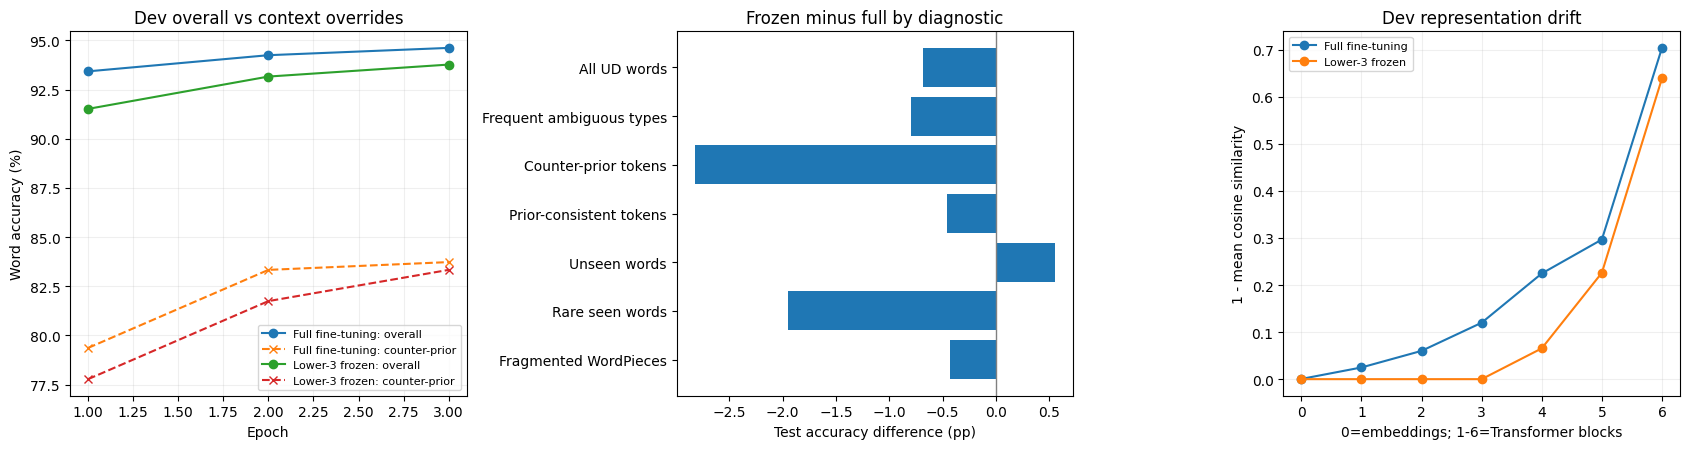

In [11]:
results_df.to_csv(output_dir / "model_comparison.csv", index=False)
history_df.to_csv(output_dir / "epoch_history.csv", index=False)
slice_df.to_csv(output_dir / "diagnostic_slices.csv", index=False)
drift_df.to_csv(output_dir / "representation_drift.csv", index=False)
paired.to_csv(output_dir / "paired_word_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for name, hist in history_df.groupby("experiment", sort=False):
    axes[0].plot(hist["epoch"], hist["val_accuracy"] * 100, marker="o", label=f"{name}: overall")
    axes[0].plot(hist["epoch"], hist["val_counterprior_accuracy"] * 100,
                 marker="x", linestyle="--", label=f"{name}: counter-prior")
axes[0].set(title="Dev overall vs context overrides", xlabel="Epoch", ylabel="Word accuracy (%)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

plot_rows = slice_df[slice_df["n_words"] > 0].iloc[:].copy()
axes[1].barh(plot_rows["slice"], plot_rows["delta_pp"])
axes[1].axvline(0, color="gray", lw=1)
axes[1].invert_yaxis()
axes[1].set(title="Frozen minus full by diagnostic", xlabel="Test accuracy difference (pp)")

for name, frame in drift_df[drift_df["slice"] == "all"].groupby("experiment", sort=False):
    axes[2].plot(frame["layer"], frame["mean_cosine_drift"], marker="o", label=name)
axes[2].set(title="Dev representation drift", xlabel="0=embeddings; 1-6=Transformer blocks",
            ylabel="1 - mean cosine similarity")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "research_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

In [12]:
def fmt_pct(x):
    return "N/A" if pd.isna(x) else f"{x * 100:.2f}%"

def fmt_pp(x):
    return "N/A" if pd.isna(x) else f"{x:+.2f}"

def metric_table(frame):
    lines = [
        "| Diagnostic | Words | Full accuracy | Frozen accuracy | Frozen - full (pp) | 95% paired CI (pp) |",
        "|---|---:|---:|---:|---:|---:|",
    ]
    for r in frame.itertuples(index=False):
        ci = "N/A" if pd.isna(r.ci_95_low_pp) else f"[{r.ci_95_low_pp:+.2f}, {r.ci_95_high_pp:+.2f}]"
        label = r.slice + (" [small]" if r.exploratory_small_slice else "")
        lines.append(f"| {label} | {r.n_words} | {fmt_pct(r.full_accuracy)} | "
                     f"{fmt_pct(r.frozen_accuracy)} | {fmt_pp(r.delta_pp)} | {ci} |")
    return "\n".join(lines)

core = slice_df.set_index("slice").loc["Counter-prior tokens"]
context_delta = core["delta_pp"]
context_ci = (core["ci_95_low_pp"], core["ci_95_high_pp"])
if pd.isna(context_delta):
    context_statement = "There were no counter-prior test tokens under the selected sampling thresholds. Expand the training/test samples before interpreting this slice."
elif core["n_words"] < 100:
    context_statement = "The counter-prior sample is smaller than 100 tokens, so its observed difference is especially unstable and exploratory."
elif context_ci[0] > 0:
    context_statement = "On this particular test sample, the counter-prior paired interval favors freezing; this does not establish replication across training seeds."
elif context_ci[1] < 0:
    context_statement = "On this particular test sample, the counter-prior paired interval favors full fine-tuning; this does not establish replication across training seeds."
else:
    context_statement = "The counter-prior paired interval includes zero, so this one-seed test does not clearly distinguish the systems on that slice."

train_reduction_pct = 100 * (full_res["training_seconds"] - frozen_res["training_seconds"]) / full_res["training_seconds"]

def drift_value(experiment, layer, slice_name="all"):
    row = drift_df[(drift_df["experiment"] == experiment) &
                   (drift_df["layer"] == layer) &
                   (drift_df["slice"] == slice_name)]
    return float(row["mean_cosine_drift"].iloc[0])

drift_summary = [
    "| Dev representation probe | Fully trainable | Lower-3 frozen |",
    "|---|---:|---:|",
]
for depth in [0, 1, 2, 3, 4, 5, 6]:
    title = "Embeddings" if depth == 0 else f"Block {depth}"
    drift_summary.append(
        f"| {title}, all words | {drift_value('Full fine-tuning', depth):.6f} | "
        f"{drift_value('Lower-3 frozen', depth):.6f} |"
    )
drift_summary.append(
    f"| Block 6, counter-prior | {drift_value('Full fine-tuning', 6, 'counterprior'):.6f} | "
    f"{drift_value('Lower-3 frozen', 6, 'counterprior'):.6f} |"
)
wall_hours = (time.perf_counter() - start_wall) / 3600
model_summary = [
    "| Metric | Fully trainable | Lower-3 frozen |",
    "|---|---:|---:|",
    f"| Test word accuracy | {fmt_pct(full_res['test_accuracy'])} | {fmt_pct(frozen_res['test_accuracy'])} |",
    f"| Test macro-F1 | {full_res['test_macro_f1']:.4f} | {frozen_res['test_macro_f1']:.4f} |",
    f"| Best dev epoch | {full_res['best_epoch']} | {frozen_res['best_epoch']} |",
    f"| Trainable parameters | {full_res['trainable_parameters']:,} | {frozen_res['trainable_parameters']:,} |",
    f"| Training seconds (epochs only) | {full_res['training_seconds']:.1f} | {frozen_res['training_seconds']:.1f} |",
    f"| Peak allocated GPU GiB | {full_res['peak_gpu_memory_gib']:.2f} | {frozen_res['peak_gpu_memory_gib']:.2f} |",
]

report_text = f"""# When Does Partial Freezing Hurt Contextual PoS Decisions?

## Aim and focused contribution
We compared full fine-tuning and partial freezing **of the same multilingual DistilBERT checkpoint** for UD English EWT PoS tagging. Beyond overall word accuracy, we introduced a **lexical-prior override diagnostic** for *counter-prior* tokens: frequently observed ambiguous training word types whose test-context gold tag differs from their most common **training** tag. We also measured representation drift and used paired sentence-bootstrap accuracy intervals. This is an original experiment design for this task; related ideas about language-model layer probes, adaptive freezing and uncertainty already exist in the literature, so we do **not** claim a wholly new state-of-the-art algorithm.

## Experimental setup
- Data: UD English EWT **{ud_version}**, official separate train/dev/test partitions (license: CC BY-SA 4.0); sampled sentences: **{len(train_sentences)} / {len(val_sentences)} / {len(test_sentences)}** (train/dev/test).
- SHA256 of local treebank files: train `{file_sha256['train']}`, dev `{file_sha256['dev']}`, test `{file_sha256['test']}`.
- Model: `{model_name}`; six transformer blocks; same seed **{random_seed}** and initialization for both runs.
- Fine-tuning: epochs **{epochs}**, batch **{batch_size}**, max wordpieces **{max_length}**, AdamW learning rate **{learning_rate}**, weight decay **{weight_decay}**, 10% linear warmup and decay; FP16 on CUDA if available.
- Full: all model weights trained; Frozen: embeddings and Transformer blocks 1–{frozen_blocks} frozen, all remaining blocks and the PoS head trained. We chose a *contiguous lower prefix* because early contextual/lexical information may be relatively transferable and such a prefix avoids backward computation through those layers; this is a motivation, not proof that early blocks encode only syntax.
- UD labels: **17** UPOS classes; only first subwords are supervised and scored; test first-subword coverage **{test_ds.labeled_words / test_ds.total_words:.2%}** (truncated tail words excluded from scoring).
- Checkpoint: selected solely by best **dev word accuracy** (macro-F1 as tie-breaker), after which the test set was evaluated once for each model.
- Machine: **{str(device)}**; PyTorch **{torch.__version__}**; Transformers **{transformers.__version__}**.

## Measured main results
{chr(10).join(model_summary)}

Training-time reduction (full → frozen): **{train_reduction_pct:+.2f}%**; reported training times cover training minibatches, **not** downloads, tokenization, validation, probing, or plotting. A frozen parameter is not an eliminated forward-pass operation.

## Counter-prior and robustness diagnostics
A word type is eligible for the context test when it occurs at least **{min_ambig_freq}** times in the *sampled training* set with at least two distinct PoS tags. Counter-prior means the **test gold tag differs from its train-majority tag**. Rare, unseen, and fragmented groups are also reported. The 95% intervals are *paired, sentence-level percentile bootstrap* intervals ({bootstrap_repeats} draws), not confidence intervals over model random-seed variation.

{metric_table(slice_df)}

**Interpretation:** {context_statement}

For a **training-time-only** context signal (not model selection), we also logged the accuracy on *dev* counter-prior and prior-consistent tokens at every epoch in `epoch_history.csv`. The chart shows whether difficult-context tagging improved alongside overall tagging accuracy. This provides a simple observable signal to test before implementing ambiguity-triggered thawing, but it does not itself prove that thawing would help.

There were **{int(paired['full_only_correct'].sum())}** test words correctly tagged only by full fine-tuning and **{int(paired['frozen_only_correct'].sum())}** tagged correctly only by freezing. Inspect `paired_word_predictions.csv` for the actual paired examples, especially counter-prior errors.

## Mechanistic check: layer representation drift
The same **{probe_n} dev sentences** were passed through each model *before* training and at its selected final checkpoint. Drift is mean `max(0, 1 - cosine(initial_hidden, final_hidden))`, calculated only on the same first-subword word positions.

{chr(10).join(drift_summary)}

Frozen lower layers should show approximately zero drift, which verifies immobility but does **not** prove retention of abstract linguistic knowledge. See `representation_drift.csv` and `research_diagnostics.png` for the layerwise and context-slice differences. Context-dependent drift is descriptive rather than causal evidence.

## Critical discussion and limitations
1. **Capacity versus generalization:** Freezing protects pretrained weights but can impede adaptation of some syntactic decisions; effects may be positive, negative, or negligible. Comparisons of accuracy, counter-prior performance and actual wall clock make the interpretation more testable than a single aggregate result.
2. **Proxy validity:** Word/tag diversity in the sampled training set is a noisy measure of ambiguity. Majority-tag overrides select inherently difficult held-out instances. Some errors may reflect annotation disagreements. Counter-prior and prior-consistent groups also differ in their gold-tag distribution and frequency.
3. **Small, one-seed study:** Intervals resample **test sentences only**; they do not address variance from training initialization, train-set sampling or checkpoint selection. Correlated treebank documents may require document-level resampling in a larger study.
4. **Domain and truncation:** Only English EWT and a truncated subset are studied. The test word coverage is explicitly reported; dropped tail words might be systematically difficult. UD EWT gold PoS labels include conversion and correction history.
5. **No sweeping:** Frozen depth {frozen_blocks} and slice thresholds are prespecified. We did not optimize them on the test set. This is an exploratory diagnostic, not a claim of state-of-the-art or globally novel freezing.

## A specific, falsifiable next research experiment
**Ambiguity-triggered selective thawing (ATST).** Start with the same frozen embeddings + three lower blocks. Measure the *counter-prior accuracy on validation data only* at the end of epoch 1. If counter-prior validation accuracy fails to improve by a prespecified threshold in the next evaluation, unfreeze **one** adjacent lower block for the remaining updates, rather than unfreezing every block. Compare against **(a)** fixed freezing, **(b)** full fine-tuning, and **(c)** a matched-parameter or matched-compute preplanned unfreeze schedule. Keep the **test set sealed** until final selection. Hypothesis: contextual override performance may recover at lower cost than full fine-tuning. A null or negative result would falsify the proposed benefit. Evaluate both overall and counter-prior accuracy; document overhead due to changing trainable parameter sets.

**Extensions, in research priority order:** (i) repeat with **5 seeds** and frozen depths 1–5 to estimate a cost–accuracy Pareto frontier; (ii) validate the lexical-prior proxy using manual ambiguity annotations or controlled word-in-context minimal pairs; (iii) replicate in a morphologically richer UD language and study whether token fragmentation mediates differences; (iv) test whether early dev counter-prior failure predicts which language benefits from thawing, using language-held-out evaluation to avoid selection bias. These follow-ups move from a post-hoc symptom to a prospective **decision rule** about when to unfreeze.

## Time spent
- **Measured automated notebook wall time at report generation:** **{wall_hours:.2f} hours** (download/tokenization/training/evaluation/report; this is not human work time).
- **Personal implementation / reading / writing / debugging:** **[enter your actual hours]**.
- **Total hours spent to report to the instructor:** **[enter truthful total based on your work]**.

## References
- Universal Dependencies English EWT treebank and CoNLL-U data: https://universaldependencies.org/treebanks/en_ewt/ and https://github.com/UniversalDependencies/UD_English-EWT
- DistilBERT multilingual checkpoint/model card: https://huggingface.co/distilbert/distilbert-base-multilingual-cased
- Tenney, Das & Pavlick (2019), *BERT Rediscovers the Classical NLP Pipeline*: https://aclanthology.org/P19-1452/
- de Vries, van Cranenburgh & Nissim (2020), *What's so special about BERT's layers?*: https://arxiv.org/abs/2004.06499
- Bestgen (2022), *Please, Don't Forget the Difference and the Confidence Interval...*: https://arxiv.org/abs/2205.11134
- Liu et al. (2024), *AFLoRA* (adaptive freezing is related prior work, not the proposed diagnostic): https://arxiv.org/abs/2403.13269
"""
(output_dir / "research_report.md").write_text(report_text, encoding="utf-8")

serialized_results = {
    "protocol": {
        "seed": random_seed, "model_name": model_name, "ud_revision": ud_version,
        "train_sentences": len(train_sentences), "validation_sentences": len(val_sentences),
        "test_sentences": len(test_sentences), "epochs": epochs, "batch_size": batch_size,
        "max_length": max_length, "lr": learning_rate,
        "frozen_blocks": frozen_blocks, "min_ambiguous_frequency": min_ambig_freq,
        "device": str(device), "amp": amp, "data_sha256": file_sha256,
        "first_subword_test_coverage": test_ds.labeled_words / test_ds.total_words,
        "bootstrap_sentence_repeats": bootstrap_repeats,
        "automated_wall_hours": wall_hours,
    },
    "models": results_df.to_dict(orient="records"),
    "diagnostic_slices": slice_df.to_dict(orient="records"),
}
def json_safe(item):
    if isinstance(item, dict):
        return {str(k): json_safe(v) for k, v in item.items()}
    if isinstance(item, list):
        return [json_safe(v) for v in item]
    if isinstance(item, np.generic):
        return json_safe(item.item())
    if isinstance(item, float) and not np.isfinite(item):
        return None
    return item

(output_dir / "experiment_results.json").write_text(
    json.dumps(json_safe(serialized_results), indent=2, allow_nan=False), encoding="utf-8"
)

zip_base = output_dir.parent / "pos_freezing_research_results"
artifact_names = [
    "model_comparison.csv", "epoch_history.csv", "diagnostic_slices.csv",
    "representation_drift.csv", "paired_word_predictions.csv",
    "full_fine-tuning_per_tag.csv", "lower-3_frozen_per_tag.csv",
    "research_diagnostics.png", "research_report.md", "experiment_results.json",
]
import zipfile
with zipfile.ZipFile(str(zip_base) + ".zip", "w", compression=zipfile.ZIP_DEFLATED) as z:
    for filename in artifact_names:
        source = output_dir / filename
        assert source.exists(), f"Expected result missing: {source}"
        z.write(source, arcname=filename)
print("Report:", output_dir / "research_report.md")
print("Results ZIP:", str(zip_base) + ".zip")
print("Measured automated wall time:", f"{wall_hours:.2f}", "hours")

Report: /content/pos_freezing_research/research_report.md
Results ZIP: /content/pos_freezing_research_results.zip
Measured automated wall time: 0.02 hours


##download the Colab results



In [13]:
try:
    from google.colab import files
    files.download(str(zip_base) + ".zip")
except ImportError:
    print("Not in Colab; results are saved at:", str(zip_base) + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 **POS tagging entirely from scratch**

In [14]:
import gc
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import f1_score, classification_report
import matplotlib.pyplot as plt

scratch_epochs = 30
scratch_patience = 6
scratch_batch_size = 32
scratch_lr = 0.0015
scratch_word_dim = 128
scratch_char_dim = 24
scratch_char_filters = 64
scratch_lst_h = 192
scratch_lstm_layers = 2
scratch_dropout = 0.30
scratch_word_dropout = 0.15
scratch_char_limit = 24
scratch_min_word_freq = 2
scratch_save_weights = False
scratch_dir = output_dir / "scratch_from_zero"
scratch_dir.mkdir(parents=True, exist_ok=True)

assert train_sentences and val_sentences and test_sentences
assert len(set(label2id.values())) == len(tags)
set_seed(random_seed)

word_counts = Counter(w.casefold() for s in train_sentences for w in s["tokens"])
word_to_id = {"<PAD>": 0, "<UNK>": 1}
for word in sorted(word_counts):
    if word_counts[word] >= scratch_min_word_freq:
        word_to_id[word] = len(word_to_id)
char_to_id = {"<PAD>": 0, "<UNK>": 1}
for char in sorted({c for s in train_sentences for word in s["tokens"] for c in word}):
    char_to_id[char] = len(char_to_id)


def encode_scratch_chars(word):
    if len(word) > scratch_char_limit:
        front = scratch_char_limit // 2
        word = word[:front] + word[-(scratch_char_limit - front):]
    return [char_to_id.get(c, 1) for c in word] or [1]


class scratchPosDataset(Dataset):
    def __init__(self, sentences, split):
        self.items = []
        self.word_rows = []
        for sentence_i, sent in enumerate(sentences):
            tokens, tags = sent["tokens"], sent["tags"]
            assert len(tokens) == len(tags) > 0
            self.items.append({
                "word_ids": [word_to_id.get(w.casefold(), 1) for w in tokens],
                "char_ids": [encode_scratch_chars(w) for w in tokens],
                "labels": [label2id[tag] for tag in tags],
            })
            for word_i, (word, gold) in enumerate(zip(tokens, tags)):
                self.word_rows.append({
                    "sentence_index": sentence_i,
                    "source_sent_id": sent["sent_id"] or f"{split}-{sentence_i}",
                    "word_index": word_i,
                    "word": word,
                    "gold": gold,
                    "gold_id": label2id[gold],
                    **lexical_properties(word, gold),
                })
        assert len(self.word_rows) == sum(len(item["labels"]) for item in self.items)

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        return self.items[index]


def scratch_collate(items):
    lengths = torch.tensor([len(row["word_ids"]) for row in items], dtype=torch.long)
    bsz, max_words = len(items), int(lengths.max().item())
    word_ids = torch.zeros((bsz, max_words), dtype=torch.long)
    char_ids = torch.zeros((bsz, max_words, scratch_char_limit), dtype=torch.long)
    labels = torch.full((bsz, max_words), -100, dtype=torch.long)
    for i, row in enumerate(items):
        n = len(row["word_ids"])
        word_ids[i, :n] = torch.tensor(row["word_ids"], dtype=torch.long)
        labels[i, :n] = torch.tensor(row["labels"], dtype=torch.long)
        for j, chars in enumerate(row["char_ids"]):
            char_ids[i, j, :len(chars)] = torch.tensor(chars, dtype=torch.long)
    return {"word_ids": word_ids, "char_ids": char_ids,
            "lengths": lengths, "labels": labels}


scratch_train_ds = scratchPosDataset(train_sentences, "train")
scratch_val_ds = scratchPosDataset(val_sentences, "dev")
scratch_test_ds = scratchPosDataset(test_sentences, "test")


def scratch_loader(ds, shuffle=False):
    return DataLoader(
        ds, batch_size=scratch_batch_size, shuffle=shuffle,
        generator=torch.Generator().manual_seed(random_seed) if shuffle else None,
        collate_fn=scratch_collate, num_workers=0,
        pin_memory=(device.type == "cuda"),
    )


scratch_train_loader = scratch_loader(scratch_train_ds, shuffle=True)
scratch_val_loader = scratch_loader(scratch_val_ds)
scratch_test_loader = scratch_loader(scratch_test_ds)
assert scratch_test_ds.word_rows[0]["word"] == test_sentences[0]["tokens"][0]
print(f"Scratch vocabulary: {len(word_to_id):,} training words; {len(char_to_id):,} characters")
print(f"Data: {len(train_sentences):,} train, {len(val_sentences):,} dev, {len(test_sentences):,} test sentences")
print("Counter-prior test occurrences:", sum(r["counterprior"] for r in scratch_test_ds.word_rows))


Scratch vocabulary: 2,492 training words; 96 characters
Data: 2,000 train, 300 dev, 500 test sentences
Counter-prior test occurrences: 354


In [15]:
class charCnnBilstmpos(nn.Module):
    def __init__(self, n_words, n_chars, n_tags):
        super().__init__()
        self.word_embedding = nn.Embedding(n_words, scratch_word_dim, padding_idx=0)
        self.char_embedding = nn.Embedding(n_chars, scratch_char_dim, padding_idx=0)
        self.char_conv = nn.Conv1d(scratch_char_dim, scratch_char_filters,
                                   kernel_size=3, padding=1)
        self.dropout = nn.Dropout(scratch_dropout)
        self.lstm = nn.LSTM(
            scratch_word_dim + scratch_char_filters, scratch_lst_h,
            num_layers=scratch_lstm_layers, batch_first=True, bidirectional=True,
            dropout=scratch_dropout if scratch_lstm_layers > 1 else 0.0,
        )
        self.classifier = nn.Linear(2 * scratch_lst_h, n_tags)

    def forward(self, word_ids, char_ids, lengths):
        bsz, seq_len = word_ids.shape
        if self.training and scratch_word_dropout > 0:
            hide = (torch.rand(word_ids.shape, device=word_ids.device) < scratch_word_dropout)
            word_ids = word_ids.masked_fill(hide & (word_ids != 0), 1)
        words = self.word_embedding(word_ids)
        chars = self.char_embedding(char_ids.reshape(bsz * seq_len, -1))
        chars = torch.relu(self.char_conv(chars.transpose(1, 2))).amax(-1)
        chars = chars.reshape(bsz, seq_len, scratch_char_filters)
        chars = chars * (char_ids != 0).any(-1).unsqueeze(-1)
        x = self.dropout(torch.cat([words, chars], dim=-1))
        packed = pack_padded_sequence(
            x, lengths.detach().cpu(), batch_first=True, enforce_sorted=False
        )
        packed_output, _ = self.lstm(packed)
        contextual, _ = pad_packed_sequence(
            packed_output, batch_first=True, total_length=seq_len
        )
        return self.classifier(self.dropout(contextual))


def scratch_move(batch):
    return {key: value.to(device, non_blocking=(device.type == "cuda"))
            for key, value in batch.items()}


@torch.inference_mode()
def scratch_evaluate(model, loader, ds):
    model.eval()
    gold_ids, predictions = [], []
    for raw in loader:
        batch = scratch_move(raw)
        logits = model(batch["word_ids"], batch["char_ids"], batch["lengths"])
        keep = batch["labels"] != -100
        gold_ids.extend(batch["labels"][keep].cpu().tolist())
        predictions.extend(logits.argmax(-1)[keep].cpu().tolist())
    assert gold_ids == [r["gold_id"] for r in ds.word_rows], "POS alignment failure"
    assert len(gold_ids) == len(predictions) > 0
    accuracy = float(np.mean(np.asarray(gold_ids) == np.asarray(predictions)))
    macro_f1 = float(f1_score(gold_ids, predictions, labels=list(range(len(tags))),
                              average="macro", zero_division=0))
    return {"accuracy": accuracy, "macro_f1": macro_f1,
            "gold_ids": gold_ids, "predictions": predictions, "words": len(gold_ids)}


def train_scratch_model():
    set_seed(random_seed)
    if device.type == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    model = charCnnBilstmpos(len(word_to_id), len(char_to_id), len(tags)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=scratch_lr, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.6, patience=2, min_lr=0.0001
    )
    criterion = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=0.02)
    best_accuracy, best_f1, best_epoch, best_state = -1.0, -1.0, None, None
    patience_left, train_seconds, history = scratch_patience, 0.0, []
    run_start = time.perf_counter()
    val_counter_mask = np.asarray([r["counterprior"] for r in scratch_val_ds.word_rows], dtype=bool)
    val_prior_mask = np.asarray([r["prior_consistent"] for r in scratch_val_ds.word_rows], dtype=bool)

    for epoch in range(1, scratch_epochs + 1):
        model.train()
        losses = []
        if device.type == "cuda":
            torch.cuda.synchronize()
        epoch_start = time.perf_counter()
        for raw in scratch_train_loader:
            batch = scratch_move(raw)
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch["word_ids"], batch["char_ids"], batch["lengths"])
            loss = criterion(logits.reshape(-1, len(tags)), batch["labels"].reshape(-1))
            if not torch.isfinite(loss).item():
                raise FloatingPointError("Scratch model encountered a non-finite training loss")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            losses.append(float(loss.detach().cpu()))
        if device.type == "cuda":
            torch.cuda.synchronize()
        elapsed = time.perf_counter() - epoch_start
        train_seconds += elapsed
        val = scratch_evaluate(model, scratch_val_loader, scratch_val_ds)
        scheduler.step(val["accuracy"])
        correct = np.asarray(val["gold_ids"]) == np.asarray(val["predictions"])
        counter_accuracy = float(correct[val_counter_mask].mean()) if val_counter_mask.any() else float("nan")
        prior_accuracy = float(correct[val_prior_mask].mean()) if val_prior_mask.any() else float("nan")
        history.append({
            "experiment": "From scratch: CharCNN-BiLSTM", "epoch": epoch,
            "train_loss": float(np.mean(losses)), "val_accuracy": val["accuracy"],
            "val_macro_f1": val["macro_f1"],
            "val_counterprior_accuracy": counter_accuracy,
            "val_counterprior_words": int(val_counter_mask.sum()),
            "val_prior_consistent_accuracy": prior_accuracy,
            "val_prior_consistent_words": int(val_prior_mask.sum()),
            "epoch_train_seconds": elapsed, "learning_rate": optimizer.param_groups[0]["lr"],
        })
        print(f"Scratch epoch {epoch:02d}/{scratch_epochs}: loss={np.mean(losses):.3f} "
              f"dev accuracy={val['accuracy']:.2%} dev macro-F1={val['macro_f1']:.3f} "
              f"dev counter-prior={counter_accuracy:.2%} ({elapsed:.1f}s)")

        improved = (val["accuracy"] > best_accuracy + 1e-10 or
                    (abs(val["accuracy"] - best_accuracy) <= 1e-10 and
                     val["macro_f1"] > best_f1 + 1e-10))
        if improved:
            best_accuracy, best_f1, best_epoch = val["accuracy"], val["macro_f1"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_left = scratch_patience
        else:
            patience_left -= 1
            if patience_left == 0:
                print("Early stopping: validation accuracy stopped improving.")
                break

    assert best_state is not None
    model.load_state_dict(best_state)
    test = scratch_evaluate(model, scratch_test_loader, scratch_test_ds)
    params = sum(p.numel() for p in model.parameters())
    results = {
        "experiment": "From scratch: CharCNN-BiLSTM",
        "test_accuracy": test["accuracy"], "test_macro_f1": test["macro_f1"],
        "test_words": test["words"], "best_epoch": best_epoch,
        "best_val_accuracy": best_accuracy, "training_seconds": train_seconds,
        "wall_seconds": time.perf_counter() - run_start,
        "total_parameters": params, "trainable_parameters": params,
        "peak_gpu_memory_gib": (float(torch.cuda.max_memory_allocated() / 1024**3)
                                if device.type == "cuda" else float("nan")),
        "pretrained": False,
    }
    if scratch_save_weights:
        torch.save({
            "state_dict": best_state, "word_to_id": word_to_id,
            "char_to_id": char_to_id, "tags": tags,
        }, scratch_dir / "scratch_model.pt")
    print(f"\nScratch model: BEST dev epoch {best_epoch}; TEST accuracy="
          f"{test['accuracy']:.2%}, macro-F1={test['macro_f1']:.4f}")
    return results, pd.DataFrame(history), test


In [16]:
scratch_result, scratch_history, scratch_test = train_scratch_model()
scratch_words = pd.DataFrame(scratch_test_ds.word_rows)
scratch_words["predicted_id"] = scratch_test["predictions"]
scratch_words["predicted_tag"] = [id2label[idx] for idx in scratch_test["predictions"]]
scratch_words["scratch_correct"] = scratch_words["gold_id"] == scratch_words["predicted_id"]
assert len(scratch_words) == scratch_result["test_words"]
assert int(scratch_words["scratch_correct"].sum()) == sum(
    g == p for g, p in zip(scratch_test["gold_ids"], scratch_test["predictions"])
)
print("Scratch test words:", len(scratch_words), "counter-prior:", int(scratch_words["counterprior"].sum()))


Scratch epoch 01/30: loss=1.696 dev accuracy=71.46% dev macro-F1=0.523 dev counter-prior=36.51% (5.7s)
Scratch epoch 02/30: loss=0.945 dev accuracy=78.48% dev macro-F1=0.662 dev counter-prior=48.41% (2.0s)
Scratch epoch 03/30: loss=0.766 dev accuracy=82.03% dev macro-F1=0.709 dev counter-prior=57.14% (2.0s)
Scratch epoch 04/30: loss=0.660 dev accuracy=85.79% dev macro-F1=0.758 dev counter-prior=66.67% (2.0s)
Scratch epoch 05/30: loss=0.591 dev accuracy=87.94% dev macro-F1=0.793 dev counter-prior=66.67% (2.0s)
Scratch epoch 06/30: loss=0.533 dev accuracy=88.50% dev macro-F1=0.811 dev counter-prior=67.86% (2.0s)
Scratch epoch 07/30: loss=0.490 dev accuracy=89.53% dev macro-F1=0.796 dev counter-prior=69.84% (2.0s)
Scratch epoch 08/30: loss=0.463 dev accuracy=89.72% dev macro-F1=0.812 dev counter-prior=71.43% (2.0s)
Scratch epoch 09/30: loss=0.432 dev accuracy=90.38% dev macro-F1=0.836 dev counter-prior=76.19% (2.0s)
Scratch epoch 10/30: loss=0.403 dev accuracy=90.67% dev macro-F1=0.835 de

In [17]:
baseline_words = None
if "paired" in globals() and isinstance(paired, pd.DataFrame) and not paired.empty:
    baseline_words = paired.copy()
elif (output_dir / "paired_word_predictions.csv").exists():
    baseline_words = pd.read_csv(output_dir / "paired_word_predictions.csv")

scratch_comp = scratch_words.copy()
baseline_available = baseline_words is not None
if baseline_available:
    keys = ["sentence_index", "word_index"]
    baseline_cols = keys + ["gold_id", "full_correct", "frozen_correct", "full_tag", "frozen_tag"]
    needed = set(baseline_cols)
    if not needed.issubset(baseline_words.columns):
        raise ValueError(f"Existing baseline predictions lack columns: {sorted(needed - set(baseline_words.columns))}")
    scratch_comp = scratch_comp.merge(
        baseline_words[baseline_cols], on=keys, how="inner",
        validate="one_to_one", suffixes=("", "_baseline"),
    )
    if scratch_comp.empty or not (scratch_comp["gold_id"] == scratch_comp["gold_id_baseline"]).all():
        raise AssertionError("Mismatched test data: scratch and baseline must use identical samples")
    assert len(scratch_comp) == len(baseline_words), "Unexpected missing baseline-aligned words"
    scratch_comp["full_correct"] = scratch_comp["full_correct"].astype(bool)
    scratch_comp["frozen_correct"] = scratch_comp["frozen_correct"].astype(bool)
    print(f"Exact paired comparison: {len(scratch_comp):,} identical UD test word positions")
    if len(scratch_comp) < len(scratch_words):
        print("Note: comparison uses only positions scored by the pretrained models;"
              " standalone scratch test accuracy is reported separately.")
else:
    print("No original word-level predictions found. Scratch results will be shown alone.")
    print("To compare automatically, first run the original experiments, or keep"
          " paired_word_predictions.csv in OUTPUT_DIR.")


def scratch_sentence_bootstrap(frame, reference_column, repeats=2000, seed=random_seed):
    if frame.empty:
        return float("nan"), float("nan"), float("nan")
    by_sentence = frame.groupby("sentence_index")[["scratch_correct", reference_column]].sum()
    n_by_sentence = frame.groupby("sentence_index").size()
    sentence_ids = np.arange(len(test_sentences))
    scratch_hits = by_sentence["scratch_correct"].reindex(sentence_ids, fill_value=0).to_numpy()
    baseline_hits = by_sentence[reference_column].reindex(sentence_ids, fill_value=0).to_numpy()
    counts = n_by_sentence.reindex(sentence_ids, fill_value=0).to_numpy()
    rng = np.random.default_rng(seed)
    sample = rng.integers(0, len(sentence_ids), size=(repeats, len(sentence_ids)))
    denominator = counts[sample].sum(axis=1)
    valid = denominator > 0
    if not valid.any():
        return float("nan"), float("nan"), float("nan")
    differences = 100 * (scratch_hits[sample].sum(axis=1) - baseline_hits[sample].sum(axis=1))
    differences = differences[valid] / denominator[valid]
    observed = 100 * (frame["scratch_correct"].mean() - frame[reference_column].mean())
    return float(observed), float(np.quantile(differences, 0.025)), float(np.quantile(differences, 0.975))


scratch_slices = {
    "All UD words": np.ones(len(scratch_comp), dtype=bool),
    "Frequent ambiguous types": scratch_comp["ambiguous_type"].to_numpy(dtype=bool),
    "Counter-prior tokens": scratch_comp["counterprior"].to_numpy(dtype=bool),
    "Prior-consistent tokens": scratch_comp["prior_consistent"].to_numpy(dtype=bool),
    "Unseen words": (scratch_comp["lexical_group"] == "unseen").to_numpy(),
    "Rare seen words": (scratch_comp["lexical_group"] == "rare_seen").to_numpy(),
}
scratch_slice_rows = []
for i, (slice_name, mask) in enumerate(scratch_slices.items()):
    subset = scratch_comp.loc[mask]
    row = {
        "slice": slice_name, "n_words": len(subset),
        "n_sentences": int(subset["sentence_index"].nunique()),
        "scratch_accuracy": float(subset["scratch_correct"].mean()) if len(subset) else float("nan"),
    }
    if baseline_available:
        for base in ("full", "frozen"):
            row[f"{base}_accuracy"] = float(subset[f"{base}_correct"].mean()) if len(subset) else float("nan")
            delta, low, high = scratch_sentence_bootstrap(
                subset, f"{base}_correct", seed=random_seed + 10 * i + (0 if base == "full" else 1)
            )
            row[f"scratch_minus_{base}_pp"] = delta
            row[f"scratch_minus_{base}_ci_low_pp"] = low
            row[f"scratch_minus_{base}_ci_high_pp"] = high
    scratch_slice_rows.append(row)
scratch_slice_df = pd.DataFrame(scratch_slice_rows)
print("\n=== From-scratch results on the same diagnostic groups ===")
print(scratch_slice_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

print("\n=== Counter-prior errors from the scratch model (illustrative) ===")
example_cols = ["source_sent_id", "word", "gold", "lexical_prior_tag", "predicted_tag"]
if baseline_available:
    example_cols += ["full_tag", "frozen_tag"]
errors = scratch_comp.loc[
    scratch_comp["counterprior"] & ~scratch_comp["scratch_correct"], example_cols
].head(20)
print("No errors in this group." if errors.empty else errors.to_string(index=False))


Exact paired comparison: 6,096 identical UD test word positions

=== From-scratch results on the same diagnostic groups ===
                   slice  n_words  n_sentences  scratch_accuracy  full_accuracy  scratch_minus_full_pp  scratch_minus_full_ci_low_pp  scratch_minus_full_ci_high_pp  frozen_accuracy  scratch_minus_frozen_pp  scratch_minus_frozen_ci_low_pp  scratch_minus_frozen_ci_high_pp
            All UD words     6096          500             0.921          0.947                 -2.575                        -3.356                         -1.790            0.940                   -1.886                          -2.638                           -1.098
Frequent ambiguous types     2508          396             0.944          0.961                 -1.675                        -2.613                         -0.711            0.953                   -0.877                          -1.851                            0.078
    Counter-prior tokens      354          210             0.74

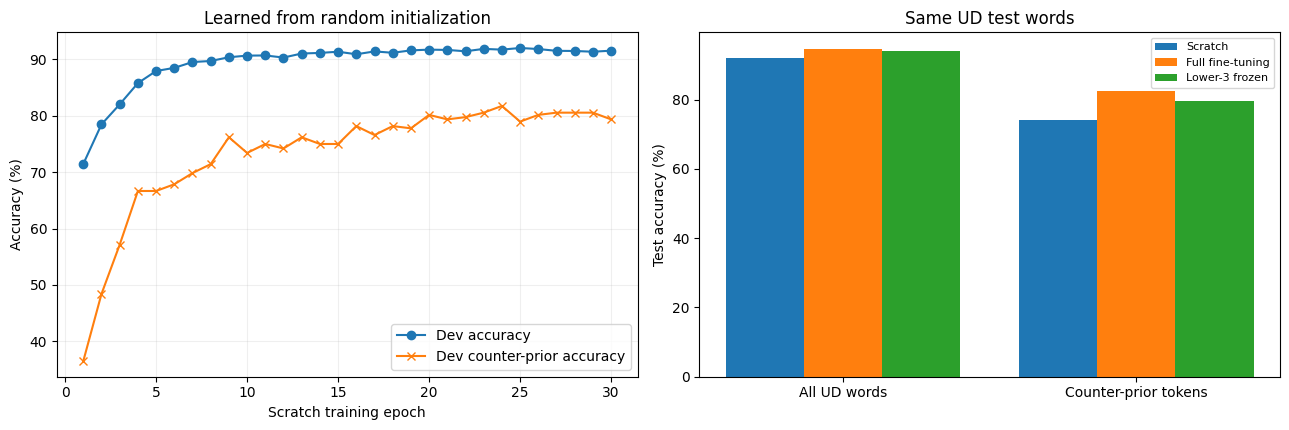

Scratch report: /content/pos_freezing_research/scratch_from_zero/scratch_report.md
Scratch results ZIP: /content/pos_freezing_research/scratch_from_zero/scratch_results.zip


In [18]:
import json
import zipfile

scratch_history.to_csv(scratch_dir / "epoch_history.csv", index=False)
scratch_words.to_csv(scratch_dir / "word_predictions.csv", index=False)
scratch_comp.to_csv(scratch_dir / "paired_word_predictions.csv", index=False)
scratch_slice_df.to_csv(scratch_dir / "diagnostic_slices.csv", index=False)
pd.DataFrame([scratch_result]).to_csv(scratch_dir / "model_metrics.csv", index=False)
errors.to_csv(scratch_dir / "counterprior_errors.csv", index=False)

per_tag = classification_report(
    scratch_test["gold_ids"], scratch_test["predictions"],
    labels=list(range(len(tags))), target_names=tags,
    output_dict=True, zero_division=0,
)
pd.DataFrame(per_tag).T.to_csv(scratch_dir / "per_tag_scores.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].plot(scratch_history["epoch"], scratch_history["val_accuracy"] * 100,
            label="Dev accuracy", marker="o")
axs[0].plot(scratch_history["epoch"], scratch_history["val_counterprior_accuracy"] * 100,
            label="Dev counter-prior accuracy", marker="x")
axs[0].set(xlabel="Scratch training epoch", ylabel="Accuracy (%)", title="Learned from random initialization")
axs[0].legend()
axs[0].grid(alpha=0.2)
plot_slices = scratch_slice_df[scratch_slice_df["slice"].isin(["All UD words", "Counter-prior tokens"])]
plot_names = plot_slices["slice"].tolist()
vals = [plot_slices["scratch_accuracy"].to_numpy() * 100]
labels = ["Scratch"]
if baseline_available:
    vals += [plot_slices["full_accuracy"].to_numpy() * 100,
             plot_slices["frozen_accuracy"].to_numpy() * 100]
    labels += ["Full fine-tuning", "Lower-3 frozen"]
idx = np.arange(len(plot_names))
width = 0.8 / len(vals)
for j, (metric_vals, label) in enumerate(zip(vals, labels)):
    axs[1].bar(idx - 0.4 + width * (j + 0.5), metric_vals, width, label=label)
axs[1].set_xticks(idx, plot_names)
axs[1].set(ylabel="Test accuracy (%)", title="Same UD test words")
axs[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(scratch_dir / "scratch_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()


def pct(v):
    return "N/A" if pd.isna(v) else f"{v:.2%}"


def fmt_delta(v):
    return "N/A" if pd.isna(v) else f"{v:+.2f} pp"


counter_row = scratch_slice_df.set_index("slice").loc["Counter-prior tokens"]
report = [
    "# POS tagging with a model trained entirely from scratch",
    "",
    f"- UD English EWT: {ud_version}; seed {random_seed}.",
    f"- Original dataset sampling: {len(train_sentences):,} train, {len(val_sentences):,} dev, {len(test_sentences):,} test sentences.",
    "- Randomly initialized architecture: train-only word embeddings + char-CNN + bidirectional LSTM + token classifier.",
    "- No pretrained tokenizer, embeddings, encoder, or model weights used by this new model.",
    "- Checkpoint selected by validation word accuracy (macro-F1 tie-break); final test used once.",
    f"- Best epoch: {scratch_result['best_epoch']} (maximum {scratch_epochs}, patience {scratch_patience}).",
    f"- Test word accuracy: **{pct(scratch_result['test_accuracy'])}**.",
    f"- Test macro-F1: **{scratch_result['test_macro_f1']:.4f}**.",
    f"- Test counter-prior accuracy: **{pct(counter_row['scratch_accuracy'])}** on {int(counter_row['n_words'])} tokens.",
    f"- Trainable parameters: {scratch_result['trainable_parameters']:,}.",
    f"- Training time (sum of epoch optimization): {scratch_result['training_seconds']:.1f} seconds.",
]
if baseline_available:
    for base, label in [("full", "Full fine-tuning"), ("frozen", "Lower-3 frozen")]:
        overall = scratch_slice_df.set_index("slice").loc["All UD words"]
        row = scratch_slice_df.set_index("slice").loc["Counter-prior tokens"]
        report.extend([
            "",
            f"## Compared with {label}",
            f"- Baseline overall accuracy on *identical* words: {pct(overall[f'{base}_accuracy'])}.",
            f"- Scratch minus baseline overall: {fmt_delta(overall[f'scratch_minus_{base}_pp'])}, "
            f"95% sentence-bootstrap CI [{overall[f'scratch_minus_{base}_ci_low_pp']:+.2f}, "
            f"{overall[f'scratch_minus_{base}_ci_high_pp']:+.2f}] pp.",
            f"- Baseline counter-prior accuracy: {pct(row[f'{base}_accuracy'])}.",
            f"- Scratch minus baseline counter-prior: {fmt_delta(row[f'scratch_minus_{base}_pp'])}, "
            f"95% sentence-bootstrap CI [{row[f'scratch_minus_{base}_ci_low_pp']:+.2f}, "
            f"{row[f'scratch_minus_{base}_ci_high_pp']:+.2f}] pp.",
        ])
else:
    report.extend(["", "The pretrained prediction file was unavailable, so no paired baseline comparison was computed."])
report.extend([
    "", "## Important limits", "",
    "- One random seed and small training set. Scratch starts with **no external language knowledge**; pretrained models have a major advantage.",
    "- Counter-prior tokens are selected by a training-only lexical majority rule. They are not a perfect linguistic ambiguity ground truth.",
    "- Early stopping and learning rate changes use the official dev split only. Do not tune hyperparameters on the held-out test set.",
    "- Training time depends on runtime hardware; CPU and T4 time are not directly comparable.",
    "- This report reflects the actual trained run, not predicted or guaranteed performance.",
])
(scratch_dir / "scratch_report.md").write_text("\n".join(report) + "\n", encoding="utf-8")

summary = {
    "dataset": {"ud_version": ud_version, "seed": random_seed, "train": len(train_sentences),
                "dev": len(val_sentences), "test": len(test_sentences)},
    "configuration": {"epochs": scratch_epochs, "patience": scratch_patience,
                      "batch_size": scratch_batch_size, "learning_rate": scratch_lr,
                      "word_dropout": scratch_word_dropout, "pretrained": False},
    "scratch_metrics": scratch_result,
    "diagnostic_slices": scratch_slice_df.to_dict(orient="records"),
}
def scratch_json_safe(x):
    if isinstance(x, dict):
        return {str(k): scratch_json_safe(v) for k, v in x.items()}
    if isinstance(x, list):
        return [scratch_json_safe(v) for v in x]
    if isinstance(x, np.generic):
        return scratch_json_safe(x.item())
    if isinstance(x, float) and not np.isfinite(x):
        return None
    return x

(scratch_dir / "scratch_results.json").write_text(
    json.dumps(scratch_json_safe(summary), indent=2, allow_nan=False), encoding="utf-8"
)

scratch_zip = scratch_dir / "scratch_results.zip"
with zipfile.ZipFile(scratch_zip, "w", compression=zipfile.ZIP_DEFLATED) as zipped:
    for name in ["epoch_history.csv", "word_predictions.csv", "paired_word_predictions.csv",
                 "diagnostic_slices.csv", "model_metrics.csv", "counterprior_errors.csv",
                 "per_tag_scores.csv", "scratch_diagnostics.png", "scratch_report.md", "scratch_results.json"]:
        zipped.write(scratch_dir / name, arcname=name)
print("Scratch report:", scratch_dir / "scratch_report.md")
print("Scratch results ZIP:", scratch_zip)
